In [10]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Input
from tensorflow.keras.callbacks import EarlyStopping
from openpyxl import Workbook
from openpyxl.styles import Font, PatternFill
import warnings
warnings.filterwarnings("ignore")

np.random.seed(42)
tf.random.set_seed(42)

In [20]:
def generate_applicants(n=1500):
    privileged_mask = np.random.rand(n) < 0.12   
 
    math   = np.random.randint(100, 201, n)
    eng   = np.random.randint(100, 201, n)
    ukr   = np.random.randint(100, 201, n)
 
    rating = 0.4 * math + 0.3 * eng + 0.3 * ukr
 
   
    def admission_rule(m, e, u, r, priv):
        if priv:
            return int(m >= 120 and e >= 120 and u >= 120 and r >= 144)
        else:
            return int(m >= 140 and r >= 160)
 
    admitted = np.array([
        admission_rule(math[i], eng[i], ukr[i], rating[i], privileged_mask[i])
        for i in range(n)
    ])
 
    df = pd.DataFrame({
        'ID': [f'AB{i+1:04d}' for i in range(n)],
        'Математика': math,
        'Англійська': eng,
        'Українська': ukr,
        'Рейтинг': rating.round(2),
        'Пільги': privileged_mask.astype(int),
        'Допущений': admitted
    })
    eligible = df[df["Допущений"] == 1].copy()

    privileged_df = eligible[eligible["Пільги"] == 1]
    regular_df = eligible[eligible["Пільги"] == 0]

    privileged_df = privileged_df.sort_values("Рейтинг",ascending=False).head(35)
    regular_df = regular_df.sort_values("Рейтинг",ascending=False)

    total_places = 350

    regular_places = total_places - len(privileged_df)
    regular_df = regular_df.head(regular_places)

    admitted_ids = set(
        list(privileged_df["ID"]) +
        list(regular_df["ID"])
    )

    df["Зараховано"] = df["ID"].apply(lambda x: 1 if x in admitted_ids else 0)

    return df


df = generate_applicants(1500)
total_generated = len(df)
total_privileged = df["Пільги"].sum()
total_admitted = df["Зараховано"].sum()
admitted_privileged = df[(df["Зараховано"] == 1) & (df["Пільги"] == 1)].shape[0]


print("=== ПІДСУМОК ===")
print(f"Всього згенеровано: {total_generated}")
print(f"Пільгових абітурієнтів: {total_privileged}")
print(f"Зарахованих: {total_admitted}")
print(f"Зараховані пільгові: {admitted_privileged}")

=== ПІДСУМОК ===
Всього згенеровано: 1500
Пільгових абітурієнтів: 169
Зарахованих: 350
Зараховані пільгові: 35


In [12]:

features = ['Математика', 'Англійська', 'Українська', 'Рейтинг', 'Пільги']
X = df[features].values
y = df['Зараховано'].values
 
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
 
X_train, X_test, y_train, y_test = train_test_split(
    X_scaled, y, test_size=0.2, random_state=42, stratify=y)

In [13]:
architectures = {
    "1H-4": (4,),
    "1H-8":     (8, ),
    "2H-8-4": (8, 4),
    "2H-16-8": (16, 8),
    "3H-16-8-4": (16, 8, 4),
}
 
optimizers = {
    "SGD":          lambda: tf.keras.optimizers.SGD(learning_rate=0.05,  momentum=0.0),
    "SGD+momentum": lambda: tf.keras.optimizers.SGD(learning_rate=0.05,  momentum=0.9),
    "RMSprop":      lambda: tf.keras.optimizers.RMSprop(learning_rate=0.005),
    "Adam":         lambda: tf.keras.optimizers.Adam(learning_rate=0.005),
    "Adagrad":      lambda: tf.keras.optimizers.Adagrad(learning_rate=0.05),
}

In [14]:
def build_model(hidden_layers, input_dim):

    model = Sequential()
    model.add(Input(shape=(input_dim,)))
    for units in hidden_layers:
        model.add(Dense(units, activation="relu"))
    model.add(Dense(1, activation="sigmoid"))

    return model

In [15]:
results = []
best_f1 = 0
best_model = None

print("\n--- Навчання моделей ---")

for arch_name, hidden in architectures.items():

    for opt_name, optimizer in optimizers.items():

        model = build_model(hidden, X_train.shape[1])
        model.compile(
            optimizer=optimizer(),
            loss="binary_crossentropy",
            metrics=["accuracy"]
        )

        model.fit(
            X_train,
            y_train,
            epochs=30,
            batch_size=64,
            verbose=0
        )

        y_prob = model.predict(X_test).ravel()
        y_pred = (y_prob > 0.5).astype(int)

        acc = accuracy_score(y_test, y_pred)
        f1 = f1_score(y_test, y_pred)

        results.append({
            "Архітектура": arch_name,
            "Метод":       opt_name,
            "Точність":    round(acc, 3),
            "F1":          round(f1,  3),
        })
 
        if f1 > best_f1:
            best_f1, best_model, best_arch, best_method = f1, model, arch_name, opt_name
 
     



--- Навчання моделей ---
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step 
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step 
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step 
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step 
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step 
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step 
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step 
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step 
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step 
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step 
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step 
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step 
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step 
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step 
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step 
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step 
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step 
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step 
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step 
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step 
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step 
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step 
10/10 ━━━━━━━━━

In [16]:
results_df = pd.DataFrame(results)

print(f"\n--- Порівняння архітектур (оптимізатор: {best_method}) ---")
print(f"{'Архітектура':<15} {'Точність':>10} {'F1':>10}")
print("-" * 37)
arch_view = results_df[results_df["Метод"] == best_method].sort_values("F1", ascending=False)
for _, row in arch_view.iterrows():
    print(f"{row['Архітектура']:<15} {row['Точність']:>10.3f} {row['F1']:>10.3f}")

print(f"\n--- Порівняння оптимізаторів (архітектура: {best_arch}) ---")
print(f"{'Метод':<15} {'Точність':>10} {'F1':>10}")
print("-" * 37)
opt_view = results_df[results_df["Архітектура"] == best_arch].sort_values("F1", ascending=False)
for _, row in opt_view.iterrows():
    print(f"{row['Метод']:<15} {row['Точність']:>10.3f} {row['F1']:>10.3f}")
 
print(f"\nНайкраща модель: {best_arch} / {best_method}  (F1={best_f1:.3f})")


--- Порівняння архітектур (оптимізатор: SGD+momentum) ---
Архітектура       Точність         F1
-------------------------------------
3H-16-8-4            0.997      0.993
2H-16-8              0.987      0.972
1H-4                 0.987      0.971
2H-8-4               0.980      0.958
1H-8                 0.973      0.944

--- Порівняння оптимізаторів (архітектура: 3H-16-8-4) ---
Метод             Точність         F1
-------------------------------------
SGD+momentum         0.997      0.993
Adam                 0.997      0.993
SGD                  0.993      0.986
Adagrad              0.983      0.966
RMSprop              0.977      0.952

Найкраща модель: 3H-16-8-4 / SGD+momentum  (F1=0.993)


In [17]:
y_prob = best_model.predict(X_scaled).ravel()
df["Прогноз_НМ"] = (y_prob > 0.5).astype(int)

admitted_students = df[df["Зараховано"] == 1].copy()
admitted_students = admitted_students.sort_values("Рейтинг", ascending=False)

excel_name = "admitted_students1.xlsx"

with pd.ExcelWriter(excel_name, engine="openpyxl") as writer:

    
    admitted_students.to_excel(
        writer,
        sheet_name="Зараховані",
        index=False
    )

    
    df.sort_values("Рейтинг", ascending=False).to_excel(
        writer,
        sheet_name="Всі + прогноз НМ",
        index=False
    )

    
    ws = writer.book["Зараховані"]

    header_fill = PatternFill(
        start_color="4F81BD",
        end_color="4F81BD",
        fill_type="solid"
    )

    for cell in ws[1]:
        cell.font = Font(bold=True, color="FFFFFF")
        cell.fill = header_fill

print(f"\nExcel файл збережено: {excel_name}")

47/47 ━━━━━━━━━━━━━━━━━━━━ 0s 954us/step

Excel файл збережено: admitted_students1.xlsx


[[225   5]
 [  0  70]]


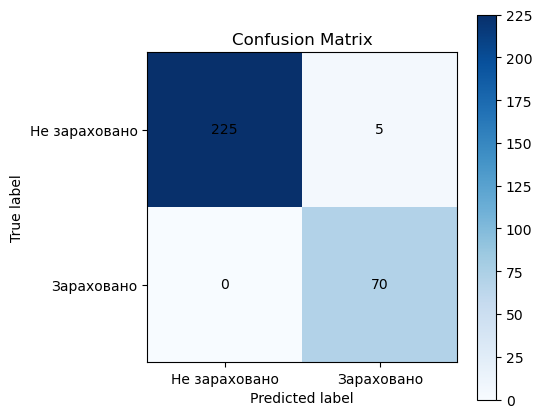

In [18]:
cm = confusion_matrix(y_test, y_pred)
print(cm)
plt.figure(figsize=(5,5))
plt.imshow(cm, cmap="Blues")

plt.title("Confusion Matrix")
plt.xlabel("Predicted label")
plt.ylabel("True label")

classes = ["Не зараховано", "Зараховано"]

plt.xticks([0,1], classes)
plt.yticks([0,1], classes)


for i in range(2):
    for j in range(2):
        plt.text(j, i, cm[i, j],
                 ha="center", va="center",
                 color="black")

plt.colorbar()
plt.show()